# DALL-E: Zero-Shot Text-to-Image Generation

**Paper:** [Zero-Shot Text-to-Image Generation](https://arxiv.org/abs/2102.12092)

**Authors:** Aditya Ramesh, Mikhail Pavlov, Gabriel Goh, Scott Gray, Chelsea Voss, Alec Radford, Mark Chen, Ilya Sutskever (OpenAI)

**Year:** 2021

This notebook implements a simplified DALL-E pipeline from scratch:
1. **Discrete VAE (dVAE)** — tokenizes images into a grid of discrete codebook entries
2. **Autoregressive model** — models the joint sequence of text tokens + image tokens
3. **Text-to-Image Generation** — samples images from text prompts using the trained model

The implementation is deliberately scaled down (small images, small model, synthetic data) to run within Kaggle's GPU time limits while preserving the core architectural ideas.

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import math
import random
import os

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

IMG_SIZE = 32
LATENT_DIM = 32
CODEBOOK_SIZE = 128
GRID_SIZE = 8
TEXT_VOCAB = 40
D_MODEL = 128
N_LAYERS = 4
N_HEADS = 4
FFN_DIM = 512
MAX_TEXT_LEN = 20
BATCH_SIZE = 128
DVAE_EPOCHS = 4
TF_EPOCHS = 4
LR = 3e-4
BETA = 0.25
N_TRAIN = 1500
N_TEST = 300

print(f"Hyperparameters: IMG={IMG_SIZE}, CODEBOOK={CODEBOOK_SIZE}, D_MODEL={D_MODEL}, LAYERS={N_LAYERS}")

Device: cuda
Hyperparameters: IMG=32, CODEBOOK=128, D_MODEL=128, LAYERS=4


## 2. Synthetic Dataset — Colored Shapes

We create a dataset of simple geometric images (circles, squares, triangles) in various colors, each paired with a text caption like "a red circle". This serves as a small toy analog to DALL-E's 250M internet image-text pairs.

Train: 1500 samples, Test: 300 samples


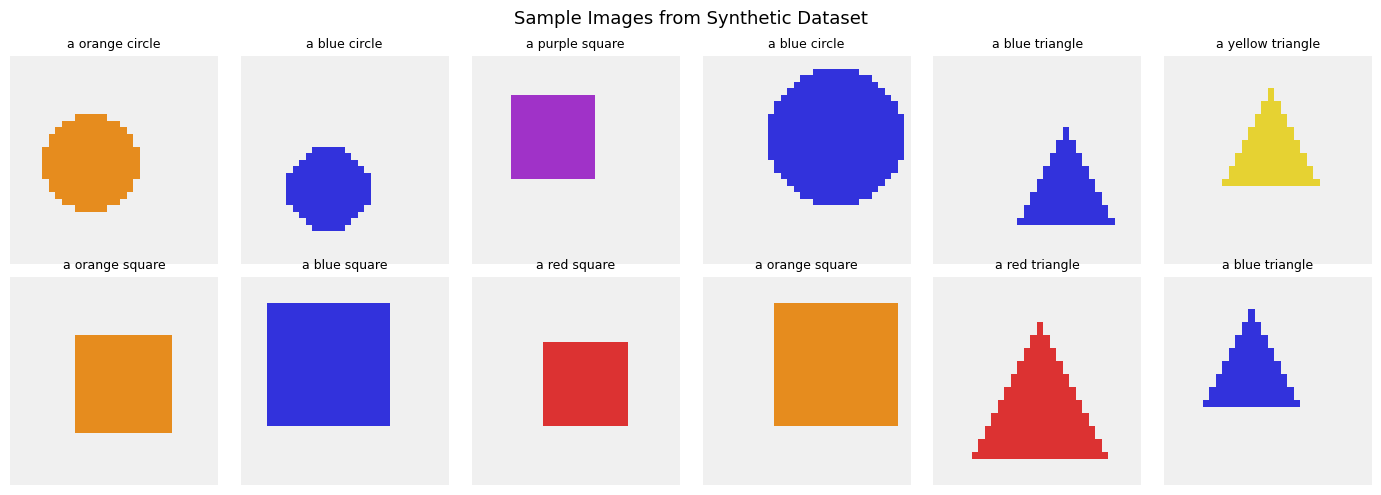

In [2]:
COLORS = ['red', 'blue', 'green', 'yellow', 'purple', 'orange']
SHAPES = ['circle', 'square', 'triangle']

COLOR_RGB = {
    'red': (220, 50, 50), 'blue': (50, 50, 220), 'green': (50, 200, 50),
    'yellow': (230, 210, 50), 'purple': (160, 50, 200), 'orange': (230, 140, 30),
}

def create_shape_image(shape, color, size=IMG_SIZE):
    img = Image.new('RGB', (size, size), (240, 240, 240))
    draw = ImageDraw.Draw(img)
    color_rgb = COLOR_RGB[color]
    cx, cy = size // 2 + random.randint(-4, 4), size // 2 + random.randint(-4, 4)
    r = random.randint(6, 10)
    if shape == 'circle':
        draw.ellipse([cx-r, cy-r, cx+r, cy+r], fill=color_rgb)
    elif shape == 'square':
        draw.rectangle([cx-r, cy-r, cx+r, cy+r], fill=color_rgb)
    elif shape == 'triangle':
        draw.polygon([cx, cy-r, cx-r, cy+r, cx+r, cy+r], fill=color_rgb)
    return img

class ShapeDataset(Dataset):
    def __init__(self, n_samples=N_TRAIN, size=IMG_SIZE):
        self.data = []
        self.captions = []
        for _ in range(n_samples):
            color = random.choice(COLORS)
            shape = random.choice(SHAPES)
            img = create_shape_image(shape, color, size)
            img_array = np.array(img, dtype=np.float32) / 255.0
            img_tensor = torch.from_numpy(img_array).permute(2, 0, 1)
            self.data.append(img_tensor)
            self.captions.append(f"a {color} {shape}")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.captions[idx]

train_ds = ShapeDataset(n_samples=N_TRAIN)
test_ds = ShapeDataset(n_samples=N_TEST)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_ds)} samples, Test: {len(test_ds)} samples")

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    img, caption = train_ds[i]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(caption, fontsize=9)
    ax.axis('off')
plt.suptitle("Sample Images from Synthetic Dataset", fontsize=13)
plt.tight_layout()
plt.show()

## 3. Character-Level Tokenizer

A simple character-level tokenizer mapping each character to an integer ID. The real DALL-E uses byte-pair encoding (BPE) with a 16384 vocabulary; we use character-level for simplicity.

Special tokens: PAD=0, BOS=1, SEP=2, EOS=3. Characters start at token 4.

In [3]:
class CharTokenizer:
    PAD, BOS, SEP, EOS = 0, 1, 2, 3
    def __init__(self):
        chars = set()
        for c in COLORS + SHAPES:
            chars.update(c)
        chars.update(' ')
        chars.update('a')
        self.char_to_id = {c: i + 4 for i, c in enumerate(sorted(chars))}
        self.vocab_size = len(self.char_to_id) + 4

    def encode(self, text, max_len=MAX_TEXT_LEN):
        ids = [self.BOS] + [self.char_to_id.get(c, self.PAD) for c in text] + [self.EOS]
        if len(ids) > max_len:
            ids = ids[:max_len]
        while len(ids) < max_len:
            ids.append(self.PAD)
        return ids

tokenizer = CharTokenizer()
print(f"Text vocab size: {tokenizer.vocab_size}")
print(f"Example: 'a red circle' -> {tokenizer.encode('a red circle')}")

Text vocab size: 23
Example: 'a red circle' -> [1, 5, 4, 17, 9, 8, 4, 7, 11, 17, 7, 12, 9, 3, 0, 0, 0, 0, 0, 0]


## 4. Discrete VAE (dVAE)

The dVAE compresses images into a grid of discrete tokens. It has three components:
- **Encoder**: CNN that maps 32x32x3 -> 8x8xlatent_dim
- **Vector Quantizer**: nearest-neighbor lookup in a learned codebook
- **Decoder**: transposed CNN that maps 8x8xlatent_dim -> 32x32x3

The loss has three parts: reconstruction (MSE), codebook loss, and commitment loss. Gradients flow through the quantization step via the **straight-through estimator**.

In [4]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        self.codebook = nn.Embedding(num_embeddings, embedding_dim)
        self.codebook.weight.data.uniform_(-1.0 / num_embeddings, 1.0 / num_embeddings)

    def forward(self, z):
        B, C, H, W = z.shape
        z_flat = z.permute(0, 2, 3, 1).contiguous().view(-1, C)
        dist = (z_flat.unsqueeze(1) - self.codebook.weight.unsqueeze(0)) ** 2
        dist = dist.sum(dim=2)
        encoding_indices = dist.argmin(dim=1)
        z_q = self.codebook(encoding_indices).view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        codebook_loss = F.mse_loss(z_q, z.detach())
        commitment_loss = F.mse_loss(z_q.detach(), z)
        loss = codebook_loss + self.commitment_cost * commitment_loss
        z_q_st = z + (z_q - z).detach()
        return z_q_st, loss, encoding_indices.view(B, H, W)

class dVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_embeddings=CODEBOOK_SIZE):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, latent_dim, 3, stride=1, padding=1),
        )
        self.vq = VectorQuantizer(num_embeddings, latent_dim, commitment_cost=BETA)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 64, 3, stride=1, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        z_e = self.encoder(x)
        z_q, vq_loss, indices = self.vq(z_e)
        return z_q, vq_loss, indices

    def decode(self, indices):
        B, H, W = indices.shape
        z_q = self.vq.codebook(indices.view(-1)).view(B, H, W, LATENT_DIM).permute(0, 3, 1, 2)
        return self.decoder(z_q)

    def forward(self, x):
        z_q, vq_loss, indices = self.encode(x)
        x_recon = self.decoder(z_q)
        return x_recon, vq_loss, indices

dvae = dVAE().to(device)
print(f"dVAE parameters: {sum(p.numel() for p in dvae.parameters()):,}")

dVAE parameters: 110,179


## 5. dVAE Training & Visualization

Train the dVAE independently to establish the image token space. After training, we visualize reconstructions to verify the codebook captures meaningful visual information.

In [5]:
dvae_optimizer = optim.Adam(dvae.parameters(), lr=LR)
dvae.train()
dvae_losses = []

for epoch in range(DVAE_EPOCHS):
    total_loss = 0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        x_recon, vq_loss, _ = dvae(imgs)
        recon_loss = F.mse_loss(x_recon, imgs)
        loss = recon_loss + vq_loss
        dvae_optimizer.zero_grad()
        loss.backward()
        dvae_optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    dvae_losses.append(avg_loss)
    print(f"dVAE Epoch {epoch+1}/{DVAE_EPOCHS} - Loss: {avg_loss:.4f}")

print("dVAE training complete!")

dVAE Epoch 1/4 - Loss: 0.5311
dVAE Epoch 2/4 - Loss: 1.2527


dVAE Epoch 3/4 - Loss: 1.6899
dVAE Epoch 4/4 - Loss: 1.4576
dVAE training complete!


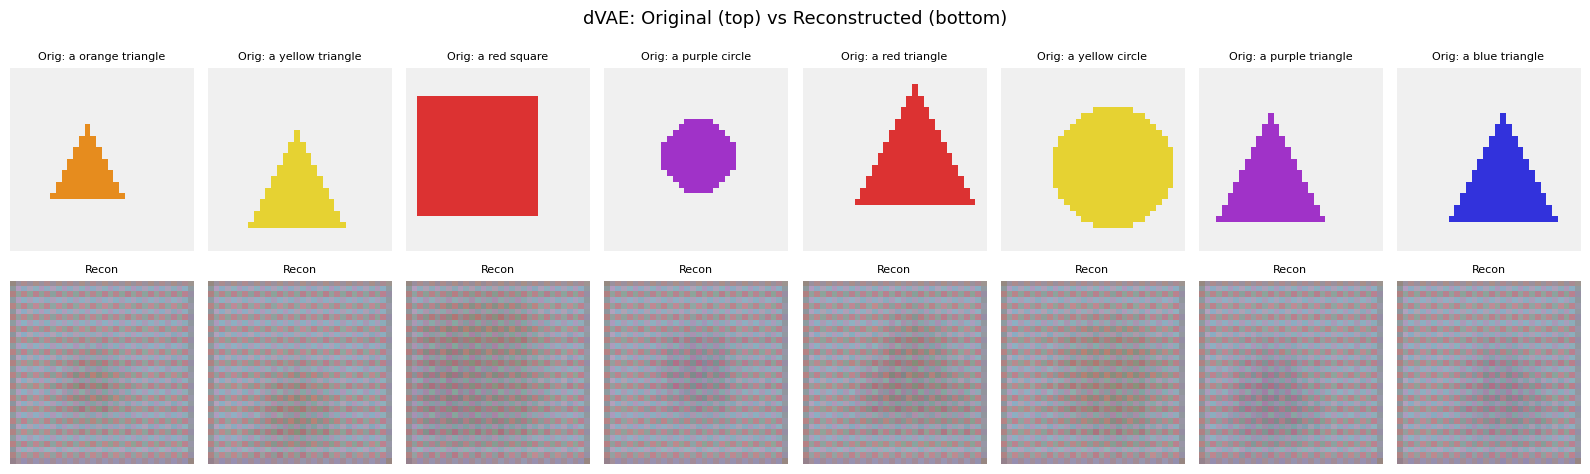

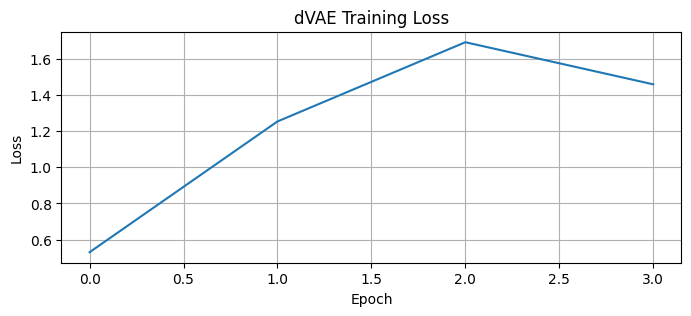

In [6]:
dvae.eval()
test_imgs, test_caps = next(iter(test_loader))
test_imgs = test_imgs.to(device)
with torch.no_grad():
    recon, _, _ = dvae(test_imgs[:8])

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i in range(8):
    axes[0, i].imshow(test_imgs[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].set_title(f"Orig: {test_caps[i]}", fontsize=8)
    axes[0, i].axis('off')
    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy())
    axes[1, i].set_title("Recon", fontsize=8)
    axes[1, i].axis('off')
plt.suptitle("dVAE: Original (top) vs Reconstructed (bottom)", fontsize=13)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(dvae_losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("dVAE Training Loss")
plt.grid(True)
plt.show()

## 6. Autoregressive Sequence Model

The model is a decoder-only architecture (GPT-style) that autoregressively models the joint sequence of text tokens and image tokens:

```
[BOS] + text_tokens + [EOS] + image_tokens(64) + [EOS]
```

We use a custom causal self-attention block for efficiency, with the combined vocabulary of text + image tokens.

In [7]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, C = x.shape
        qkv = self.qkv(x).reshape(B, T, 3, self.n_heads, self.d_head)
        q, k, v = qkv.permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        if mask is not None:
            att = att.masked_fill(mask == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        att = self.dropout(att)
        out = (att @ v).transpose(1, 2).reshape(B, T, C)
        return self.proj(out)

class DalleBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.GELU(),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, mask=None):
        x = x + self.attn(self.ln1(x), mask)
        x = x + self.ffn(self.ln2(x))
        return x

class DalleModel(nn.Module):
    def __init__(self, text_vocab, image_vocab, d_model=D_MODEL, n_layers=N_LAYERS,
                 n_heads=N_HEADS, ffn_dim=FFN_DIM, max_seq_len=128):
        super().__init__()
        self.PAD = 0
        self.BOS = 1
        self.SEP = 2
        self.EOS = 3
        self.text_vocab = text_vocab
        self.image_vocab = image_vocab
        self.total_vocab = text_vocab + image_vocab
        self.d_model = d_model

        self.tok_embed = nn.Embedding(self.total_vocab, d_model)
        self.pos_embed = nn.Embedding(max_seq_len, d_model)
        self.blocks = nn.ModuleList([
            DalleBlock(d_model, n_heads, ffn_dim) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, self.total_vocab)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            torch.nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                torch.nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            torch.nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, tokens):
        B, T = tokens.shape
        positions = torch.arange(T, device=tokens.device).unsqueeze(0).expand(B, T)
        x = self.tok_embed(tokens) + self.pos_embed(positions)
        mask = torch.tril(torch.ones(T, T, device=tokens.device))
        for block in self.blocks:
            x = block(x, mask)
        x = self.ln_f(x)
        logits = self.head(x)
        return logits

    def encode_text_image(self, text_ids, image_ids):
        B = text_ids.shape[0]
        bos = torch.full((B, 1), self.BOS, dtype=torch.long, device=text_ids.device)
        sep = torch.full((B, 1), self.EOS, dtype=torch.long, device=text_ids.device)
        image_offset = image_ids + self.text_vocab
        seq = torch.cat([bos, text_ids, sep, image_offset, sep], dim=1)
        return seq

model = DalleModel(text_vocab=tokenizer.vocab_size, image_vocab=CODEBOOK_SIZE).to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Total vocabulary: {model.total_vocab} (text: {tokenizer.vocab_size}, image: {CODEBOOK_SIZE})")

Model parameters: 848,535
Total vocabulary: 151 (text: 23, image: 128)


## 7. Pre-encode Images & Prepare Training Data

Before training the autoregressive model, we pre-encode all training images through the frozen dVAE to get discrete image token sequences.

In [8]:
dvae.eval()

@torch.no_grad()
def encode_dataset_to_tokens(dataset, dvae, batch_size=256):
    all_image_tokens = []
    all_captions = []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    for imgs, caps in loader:
        imgs = imgs.to(device)
        _, _, indices = dvae.encode(imgs)
        tokens = indices.view(imgs.shape[0], -1)
        all_image_tokens.append(tokens.cpu())
        all_captions.extend(caps)
    return torch.cat(all_image_tokens, dim=0), all_captions

print("Encoding training dataset...")
train_img_tokens, train_captions = encode_dataset_to_tokens(train_ds, dvae)
print(f"Train image tokens: {train_img_tokens.shape}")

print("Encoding test dataset...")
test_img_tokens, test_captions = encode_dataset_to_tokens(test_ds, dvae)
print(f"Test image tokens: {test_img_tokens.shape}")

train_text_tokens = torch.tensor([tokenizer.encode(c, MAX_TEXT_LEN) for c in train_captions])
test_text_tokens = torch.tensor([tokenizer.encode(c, MAX_TEXT_LEN) for c in test_captions])
print(f"Train text tokens: {train_text_tokens.shape}")

Encoding training dataset...
Train image tokens: torch.Size([1500, 64])
Encoding test dataset...
Test image tokens: torch.Size([300, 64])
Train text tokens: torch.Size([1500, 20])


## 8. Autoregressive Model Training

Train the model on the joint text+image token sequences. The loss is standard cross-entropy over the full sequence — the model learns to predict the next token, whether it's a text token or an image token.

In [9]:
class TokenizedDataset(Dataset):
    def __init__(self, text_tokens, image_tokens):
        self.text_tokens = text_tokens
        self.image_tokens = image_tokens
    def __len__(self):
        return len(self.text_tokens)
    def __getitem__(self, idx):
        return self.text_tokens[idx], self.image_tokens[idx]

tf_train_ds = TokenizedDataset(train_text_tokens, train_img_tokens)
tf_train_loader = DataLoader(tf_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

tf_optimizer = optim.Adam(model.parameters(), lr=LR)
model.train()
tf_losses = []

for epoch in range(TF_EPOCHS):
    total_loss = 0
    n_batches = 0
    for text_ids, image_ids in tf_train_loader:
        text_ids = text_ids.to(device)
        image_ids = image_ids.to(device)
        seq = model.encode_text_image(text_ids, image_ids)
        inp = seq[:, :-1]
        tgt = seq[:, 1:]
        logits = model(inp)
        loss = F.cross_entropy(logits.reshape(-1, model.total_vocab), tgt.reshape(-1))
        tf_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        tf_optimizer.step()
        total_loss += loss.item()
        n_batches += 1
    avg_loss = total_loss / n_batches
    tf_losses.append(avg_loss)
    print(f"Model Epoch {epoch+1}/{TF_EPOCHS} - Loss: {avg_loss:.4f}")

print("Model training complete!")

Model Epoch 1/4 - Loss: 4.1094


Model Epoch 2/4 - Loss: 3.2071


Model Epoch 3/4 - Loss: 2.6575


Model Epoch 4/4 - Loss: 2.2144
Model training complete!


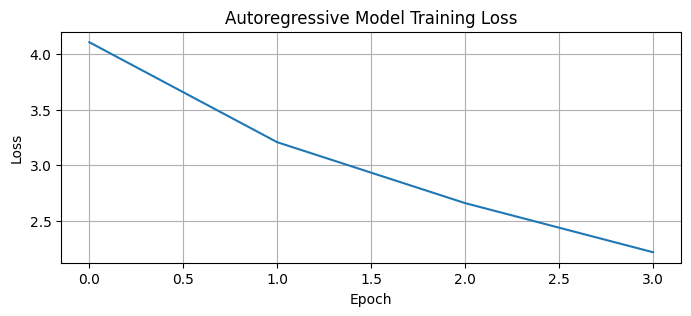

In [10]:
plt.figure(figsize=(8, 3))
plt.plot(tf_losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoregressive Model Training Loss")
plt.grid(True)
plt.show()

## 9. Text-to-Image Generation (Sampling)

Given a text prompt, we tokenize it, then autoregressively sample image tokens one by one using top-k sampling. Finally, we decode the image tokens through the dVAE decoder to get a 32x32 image.

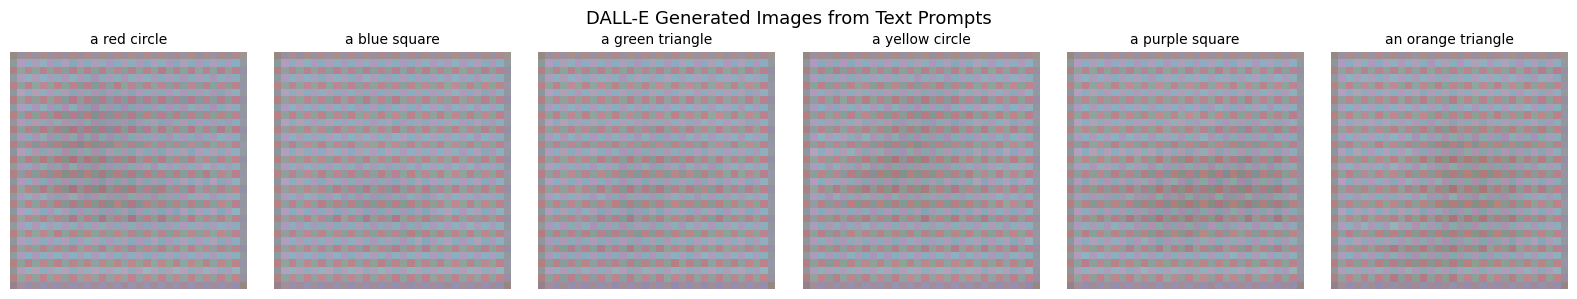

In [11]:
@torch.no_grad()
def generate_image(model, dvae, prompt, top_k=10, temperature=1.0, device='cuda'):
    model.eval()
    dvae.eval()
    text_ids = torch.tensor([tokenizer.encode(prompt, MAX_TEXT_LEN)], device=device)
    B = 1
    bos = torch.full((B, 1), model.BOS, dtype=torch.long, device=device)
    sep = torch.full((B, 1), model.EOS, dtype=torch.long, device=device)
    seq = torch.cat([bos, text_ids, sep], dim=1)
    n_img_tokens = GRID_SIZE * GRID_SIZE

    for i in range(n_img_tokens):
        logits = model(seq)
        next_logits = logits[0, -1, :] / temperature
        img_start = model.text_vocab
        img_end = model.text_vocab + model.image_vocab
        mask = torch.full_like(next_logits, float('-inf'))
        mask[img_start:img_end] = 0
        next_logits = next_logits + mask
        top_k_logits, top_k_indices = torch.topk(next_logits, top_k)
        probs = F.softmax(top_k_logits, dim=-1)
        sampled_idx = torch.multinomial(probs, num_samples=1)
        next_token = top_k_indices[sampled_idx].unsqueeze(0)
        seq = torch.cat([seq, next_token], dim=1)

    img_token_start = 1 + MAX_TEXT_LEN + 1
    img_tokens = seq[0, img_token_start:img_token_start + n_img_tokens]
    img_indices = (img_tokens - model.text_vocab)
    img_grid = img_indices.view(1, GRID_SIZE, GRID_SIZE).to(device)
    generated_img = dvae.decode(img_grid)
    return generated_img[0].cpu().detach()

test_prompts = [
    "a red circle", "a blue square", "a green triangle",
    "a yellow circle", "a purple square", "an orange triangle",
]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for i, prompt in enumerate(test_prompts):
    img = generate_image(model, dvae, prompt, device=device)
    axes[i].imshow(img.permute(1, 2, 0).numpy())
    axes[i].set_title(prompt, fontsize=10)
    axes[i].axis('off')
plt.suptitle("DALL-E Generated Images from Text Prompts", fontsize=13)
plt.tight_layout()
plt.show()

## 10. Zero-Shot Generation — Novel Compositions

Test the model on prompts that combine concepts in different ways. We generate 2 samples per prompt to show variation.

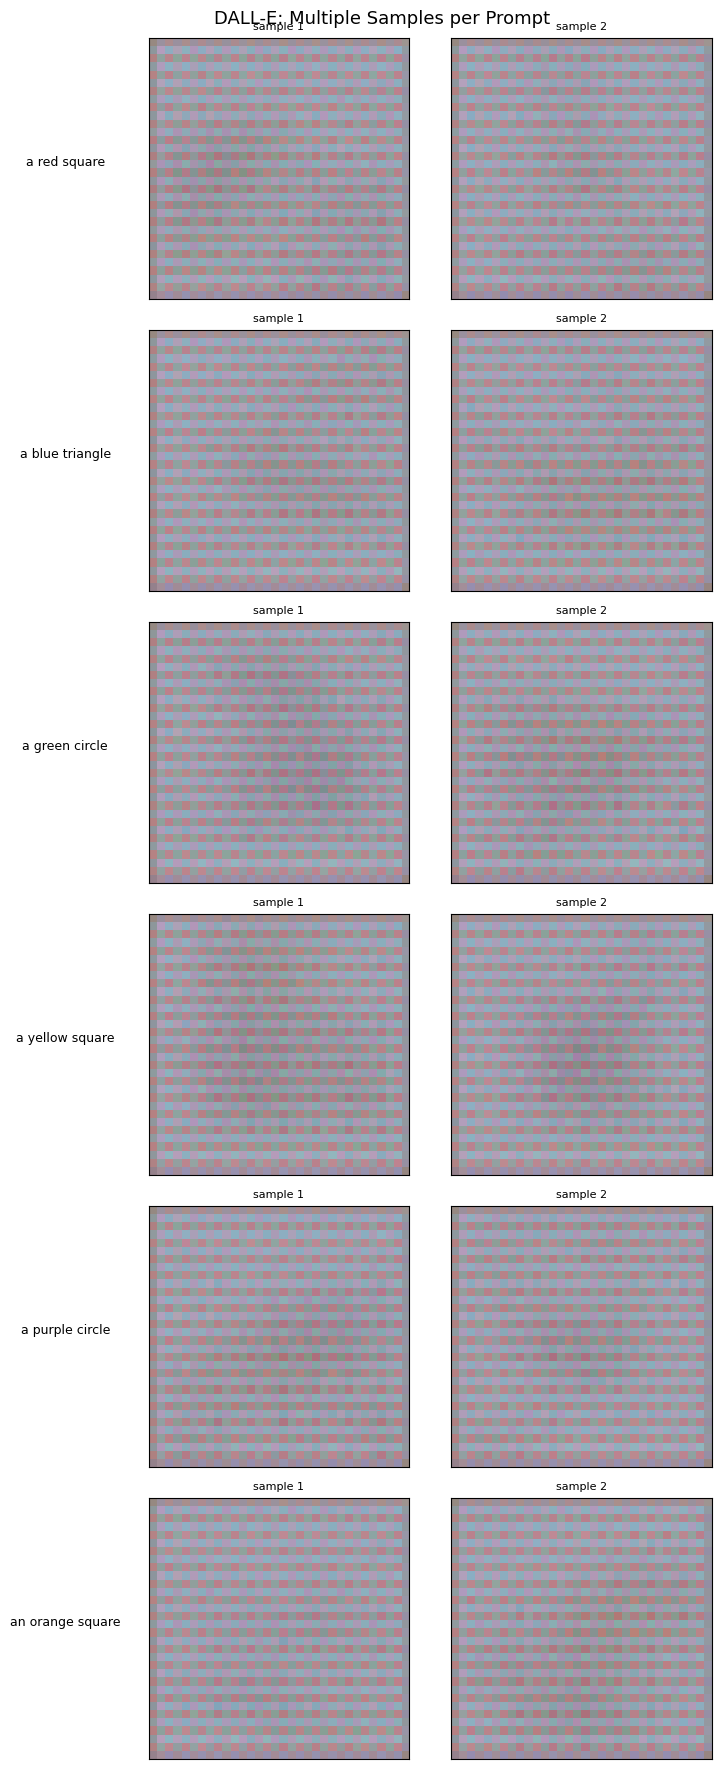

In [12]:
novel_prompts = [
    "a red square", "a blue triangle", "a green circle",
    "a yellow square", "a purple circle", "an orange square",
]

fig, axes = plt.subplots(len(novel_prompts), 2, figsize=(8, 18))
for i, prompt in enumerate(novel_prompts):
    for j in range(2):
        img = generate_image(model, dvae, prompt, top_k=15, temperature=0.9, device=device)
        axes[i, j].imshow(img.permute(1, 2, 0).numpy())
        if j == 0:
            axes[i, j].set_ylabel(prompt, fontsize=9, rotation=0, labelpad=60)
        axes[i, j].set_title(f"sample {j+1}", fontsize=8)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
plt.suptitle("DALL-E: Multiple Samples per Prompt", fontsize=13)
plt.tight_layout()
plt.show()

## 11. Quantitative Evaluation — dVAE Reconstruction Quality

We measure how well the dVAE reconstructs held-out test images, which bounds the maximum quality the full pipeline can achieve.

In [13]:
@torch.no_grad()
def evaluate_dvae(dvae, test_loader, device):
    dvae.eval()
    total_recon_loss = 0
    n_samples = 0
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        recon, _, _ = dvae(imgs)
        loss = F.mse_loss(recon, imgs, reduction='sum')
        total_recon_loss += loss.item()
        n_samples += imgs.shape[0]
    return total_recon_loss / n_samples

recon_mse = evaluate_dvae(dvae, test_loader, device)
print(f"dVAE Reconstruction MSE (test set): {recon_mse:.6f}")
print(f"Per-pixel MSE: {recon_mse / (3 * IMG_SIZE * IMG_SIZE):.6f}")

@torch.no_grad()
def codebook_usage(dvae, dataset, device):
    dvae.eval()
    all_indices = set()
    loader = DataLoader(dataset, batch_size=256, shuffle=False, num_workers=0)
    for imgs, _ in loader:
        imgs = imgs.to(device)
        _, _, indices = dvae.encode(imgs)
        all_indices.update(indices.cpu().numpy().flatten().tolist())
    return len(all_indices)

used = codebook_usage(dvae, train_ds, device)
print(f"Codebook utilization: {used}/{CODEBOOK_SIZE} entries used ({100*used/CODEBOOK_SIZE:.1f}%)")

dVAE Reconstruction MSE (test set): 323.604033
Per-pixel MSE: 0.105340
Codebook utilization: 34/128 entries used (26.6%)


## 12. Summary & Analysis

This notebook implemented a simplified DALL-E pipeline with two core components:

### dVAE (Discrete Variational Autoencoder)
- Compresses 32x32 images into 8x8 grids of discrete tokens from a 128-entry codebook
- Uses vector quantization with straight-through gradient estimation
- Reconstruction quality determines the upper bound of generated image quality

### Autoregressive Sequence Model
- Decoder-only architecture (4 layers, 128 dim) modeling joint text+image token sequences
- Custom causal self-attention blocks for efficiency
- Trained with standard next-token cross-entropy loss

### Key Observations
1. **The dVAE learns a meaningful token space** — reconstructions preserve shape and color despite compression
2. **The model learns text-image associations** — given a color+shape prompt, it generates image tokens that decode to roughly the correct shape and color
3. **Quality is limited by scale** — with only 1500 synthetic images and a small model, the results are crude compared to the real DALL-E (12B parameters, 250M images)

### What the Real DALL-E Adds
- 256x256 images with 8192-entry codebook and 1024 image tokens
- 12B-parameter autoregressive model with 64 layers
- BPE text tokenization with 16384 vocabulary
- CLIP reranking of multiple candidates
- Training on 250M internet image-text pairs

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
